<a href="https://colab.research.google.com/github/Dineshkumar-DK19/GCEE-HCL/blob/main/Phase%202%20-%20ML/UNIT%201%20-%20Machine%20Learning/Learning%20Tasks/Supervised%20/Naive_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt

In [16]:
df = pd.read_csv("Pass-Fail Data.csv")
df.head()

,student_id,attendance_pct,homework_pct,midterm_score,study_hours_per_week,pass
0,1,95,92,88,12,1
1,2,88,85,79,10,1
2,3,60,55,58,4,0
3,4,72,70,65,6,1
4,5,40,45,50,3,0


In [3]:
X= df[["attendance_pct",
    "homework_pct",
    "midterm_score",
    "study_hours_per_week"]]

y= df["pass"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [5]:
model_nb = GaussianNB()
model_nb.fit(X_train, y_train)

GaussianNB()

In [6]:
y_pred_nb = model_nb.predict(X_test)

In [7]:
print("Accuracy:", accuracy_score(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nb,
    labels=[0, 1],
    target_names=["Fail", "Pass"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb, labels=[0, 1]))

Accuracy: 0.95

Classification Report:
              precision    recall  f1-score   support

        Fail       0.89      1.00      0.94         8
        Pass       1.00      0.92      0.96        12

    accuracy                           0.95        20
   macro avg       0.94      0.96      0.95        20
weighted avg       0.96      0.95      0.95        20


Confusion Matrix:
[[ 8  0]
 [ 1 11]]


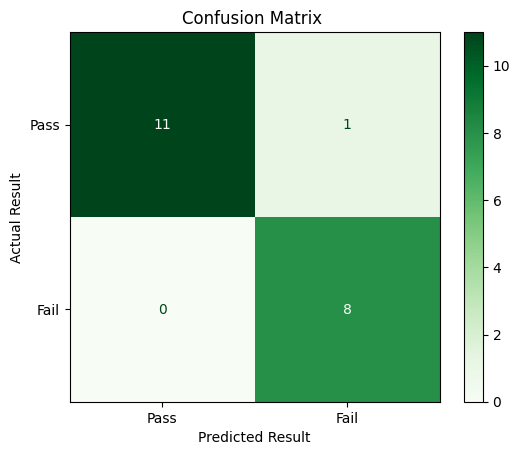

In [15]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nb,
    labels=[1, 0],
    display_labels=["Pass", "Fail"],
    cmap="Greens"
)

plt.title("Confusion Matrix ")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.show()